# Fourth-Down Conversion Prediction: Baseline and Model Comparison

**Notebook owner:** Emily  
**Project:** NFL Fourth-Down Decision Analysis

### Research Question

How accurately can machine learning models estimate the probability of a successful NFL fourth-down conversion using information available before the snap?

### Scope

This notebook uses NFL play-by-play data from the 2015–2025 seasons, including regular-season and playoff games. The analysis focuses on fourth-down rushing and passing attempts with clearly recorded conversion outcomes, excluding plays flagged for penalties under the team's shared filtering policy.

The prediction task is binary classification:

- **1:** The fourth-down attempt was successful.
- **0:** The fourth-down attempt was unsuccessful.

The dataset is divided chronologically to evaluate how models trained on historical seasons perform on newer data:

- **Training:** 2015–2022
- **Validation:** 2023
- **Test:** 2024–2025

The test set is reserved for final model evaluation and is not used for preliminary model comparisons.

### Modeling Approach

We first establish a constant-probability benchmark using the training conversion rate. We then train and evaluate three classification algorithms:

1. Logistic Regression
2. Random Forest
3. Gradient Boosting

Models are compared using accuracy, log loss, Brier score, and ROC AUC. Probability calibration is also examined because reliable conversion probabilities are important for evaluating fourth-down decisions.

This notebook builds on the shared data processing functions and the exploratory analysis documented in `02_logan_eda.ipynb`.

In [1]:
# Cell 1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    log_loss,
    brier_score_loss,
    roc_auc_score,
)

from nfl_project.data import (
    load_data,
    process_4th_down_data,
    split_data_chronological,
    make_preprocessor,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
)


In [2]:
# Cell 2

seasons = list(range(2015, 2026))

raw_data = load_data(seasons)
data = process_4th_down_data(raw_data)

print("Raw plays:", len(raw_data))
print("Fourth-down attempts:", len(data))
print("Number of features:", len(FEATURE_COLUMNS))


Raw plays: 532376
Fourth-down attempts: 7433
Number of features: 28


## Data Preparation and Train/Validation/Test Split

NFL play-by-play data from the 2015–2025 seasons was loaded using `nflreadpy` and processed through the project's shared `process_4th_down_data()` function. The original dataset contained 532,376 plays, which were filtered to 7,433 eligible fourth-down rushing and passing attempts.

The processing step excludes plays with penalties and plays without a clearly recorded conversion outcome. The binary target variable, `converted`, indicates whether an eligible fourth-down attempt successfully gained the necessary yardage.

### Chronological Split

Following the split strategy proposed in the team's exploratory analysis, the data was divided by season rather than randomly:

| Dataset | Seasons | Observations |
|---|---|---:|
| Training | 2015–2022 | 4,887 |
| Validation | 2023 | 823 |
| Test | 2024–2025 | 1,723 |

A chronological split better reflects the intended application: training on historical NFL games and predicting outcomes in future seasons. It also reduces the risk of information from newer seasons influencing training.

The training set is used to fit the models, while the validation set is used to compare model performance and guide development. The test set is held out for final evaluation.

### Features and Preprocessing

The models use 28 candidate predictors, including yards to go, field position, score differential, game time, timeouts, team identifiers, and game conditions. Additional engineered features capture situations such as short yardage, red-zone position, and late-game deficits.

Numeric features are imputed using the training-set median and standardized for Logistic Regression. Binary features use most-frequent imputation, while categorical features are imputed and one-hot encoded. Numeric scaling is omitted for the tree-based models because decision trees do not require standardized feature scales.

Preprocessing is fitted only on the training data through scikit-learn pipelines to avoid data leakage into validation and test evaluations.

In [3]:
# Cell 3

train, test, validation = split_data_chronological(data)

print("Training examples:", len(train))
print("Validation examples:", len(validation))
print("Test examples:", len(test))

print("\nTraining seasons:", sorted(train["season"].unique()))
print("Validation seasons:", sorted(validation["season"].unique()))
print("Test seasons:", sorted(test["season"].unique()))


Training examples: 4887
Validation examples: 823
Test examples: 1723

Training seasons: [np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022)]
Validation seasons: [np.int32(2023)]
Test seasons: [np.int32(2024), np.int32(2025)]


In [4]:
# Cell 4

X_train = train[FEATURE_COLUMNS]
y_train = train[TARGET_COLUMN]

X_validation = validation[FEATURE_COLUMNS]
y_validation = validation[TARGET_COLUMN]

X_test = test[FEATURE_COLUMNS]
y_test = test[TARGET_COLUMN]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))


X_train shape: (4887, 28)
y_train shape: (4887,)

Training target distribution:
converted
1    0.518314
0    0.481686
Name: proportion, dtype: float64


In [5]:
# Cell 5

# Calculate the conversion rate from training data
baseline_probability = y_train.mean()

# Predict the same probability for every validation play
baseline_probabilities = np.full(
    len(y_validation),
    baseline_probability
)

# Convert probabilities into binary predictions
baseline_predictions = (
    baseline_probabilities >= 0.5
).astype(int)

# Evaluate on validation data
baseline_accuracy = accuracy_score(
    y_validation, baseline_predictions
)

baseline_log_loss = log_loss(
    y_validation, baseline_probabilities,
    labels=[0, 1]
)

baseline_brier = brier_score_loss(
    y_validation, baseline_probabilities
)

print("Baseline probability:", baseline_probability)
print("Validation accuracy:", baseline_accuracy)
print("Validation log loss:", baseline_log_loss)
print("Validation Brier score:", baseline_brier)


Baseline probability: 0.5183138940045018
Validation accuracy: 0.5188335358444714
Validation log loss: 0.6924381493630793
Validation Brier score: 0.2496455679552369


## Baseline Models and Evaluation

### Modeling Approach

Four prediction approaches were evaluated using the 2023 validation season. All models were trained on data from 2015–2022, using the same features and target variable to allow a consistent comparison.

**Constant-Probability Benchmark**

The simplest benchmark predicts the same conversion probability for every play, equal to the conversion rate in the training dataset (approximately 51.83%). This establishes a reference for determining whether more complex models provide meaningful improvements.

**Logistic Regression**

Logistic Regression serves as the initial machine learning baseline. It estimates conversion probability from a weighted combination of the input features, transformed through the logistic function. Numeric features are standardized, and categorical variables are one-hot encoded.

**Random Forest**

Random Forest combines predictions from multiple decision trees. It can capture nonlinear relationships and interactions among variables, such as the relationship between yards to go, field position, and game situation. The initial model uses 200 trees with a maximum depth of 8 and a minimum of 10 observations per leaf.

**Gradient Boosting**

Gradient Boosting builds decision trees sequentially, with each new tree attempting to reduce the remaining prediction error. The initial model uses 200 trees, a learning rate of 0.05, a maximum tree depth of 3, and a minimum of 10 observations per leaf.

### Evaluation Metrics

Model performance is evaluated using four metrics:

- **Accuracy:** The proportion of correctly classified conversion attempts, using a probability threshold of 0.5.
- **Log Loss:** Measures the quality of predicted probabilities, with larger penalties for confident incorrect predictions.
- **Brier Score:** Measures the average squared difference between predicted conversion probabilities and actual outcomes.
- **ROC AUC:** Measures how well the model ranks successful conversions above unsuccessful attempts across classification thresholds.

Higher accuracy and ROC AUC are better, while lower log loss and Brier scores are better.

### Validation Results

| Model | Accuracy | Log Loss | Brier Score | ROC AUC |
|---|---:|---:|---:|---:|
| Constant Probability | 0.5188 | 0.6924 | 0.2496 | 0.5000 |
| Logistic Regression | 0.6379 | 0.6298 | 0.2209 | 0.6805 |
| Random Forest | 0.6318 | 0.6293 | 0.2195 | 0.7009 |
| Gradient Boosting | 0.6294 | 0.6282 | 0.2196 | 0.6920 |

All three machine learning models outperform the constant-probability benchmark across accuracy, log loss, Brier score, and ROC AUC.

Logistic Regression achieves the highest classification accuracy (63.79%). Random Forest achieves the lowest Brier score (0.2195) and highest ROC AUC (0.7009), while Gradient Boosting achieves the lowest log loss (0.6282).

The ensemble models show promising performance for probability estimation, although the differences between the three machine learning models are relatively small. Random Forest is a preliminary candidate for further evaluation, rather than a definitive winner.

These results are based exclusively on the validation season. The 2024–2025 test set remains reserved for final evaluation.

In [6]:
# Cell 6

logistic_model = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic regression training complete!")


Logistic regression training complete!


In [7]:
# Cell 7

# Predict conversion probabilities for validation plays
logistic_probabilities = logistic_model.predict_proba(
    X_validation
)[:, 1]

# Convert probabilities to binary predictions
logistic_predictions = (
    logistic_probabilities >= 0.5
).astype(int)

# Calculate evaluation metrics
logistic_accuracy = accuracy_score(
    y_validation, logistic_predictions
)

logistic_log_loss = log_loss(
    y_validation, logistic_probabilities
)

logistic_brier = brier_score_loss(
    y_validation, logistic_probabilities
)

logistic_auc = roc_auc_score(
    y_validation, logistic_probabilities
)

print("Logistic Regression Results")
print("Accuracy:", logistic_accuracy)
print("Log loss:", logistic_log_loss)
print("Brier score:", logistic_brier)
print("ROC AUC:", logistic_auc)


Logistic Regression Results
Accuracy: 0.637910085054678
Log loss: 0.6298445176565713
Brier score: 0.2208550506317285
ROC AUC: 0.6804993731223239


In [8]:
# Cell 8

results = pd.DataFrame({
    "Model": ["Constant Probability", "Logistic Regression"],
    "Accuracy": [baseline_accuracy, logistic_accuracy],
    "Log Loss": [baseline_log_loss, logistic_log_loss],
    "Brier Score": [baseline_brier, logistic_brier]
})

print(results.round(4))


                  Model  Accuracy  Log Loss  Brier Score
0  Constant Probability    0.5188    0.6924       0.2496
1   Logistic Regression    0.6379    0.6298       0.2209


                           Feature  Coefficient  Absolute Coefficient
93  categorical__surface_astroplay    -0.886832              0.886832
37         categorical__posteam_KC     0.542847              0.542847
81        categorical__defteam_SEA    -0.511167              0.511167
61        categorical__defteam_CLE     0.414907              0.414907
72         categorical__defteam_LV     0.411551              0.411551
44         categorical__posteam_NO     0.392879              0.392879
49        categorical__posteam_SEA     0.363790              0.363790
69         categorical__defteam_KC     0.339127              0.339127
34        categorical__posteam_HOU    -0.329362              0.329362
63        categorical__defteam_DEN    -0.320385              0.320385
12            numeric__log_ydstogo    -0.317842              0.317842
21                binary__overtime     0.306424              0.306424
0                 numeric__ydstogo    -0.296298              0.296298
64        categorica

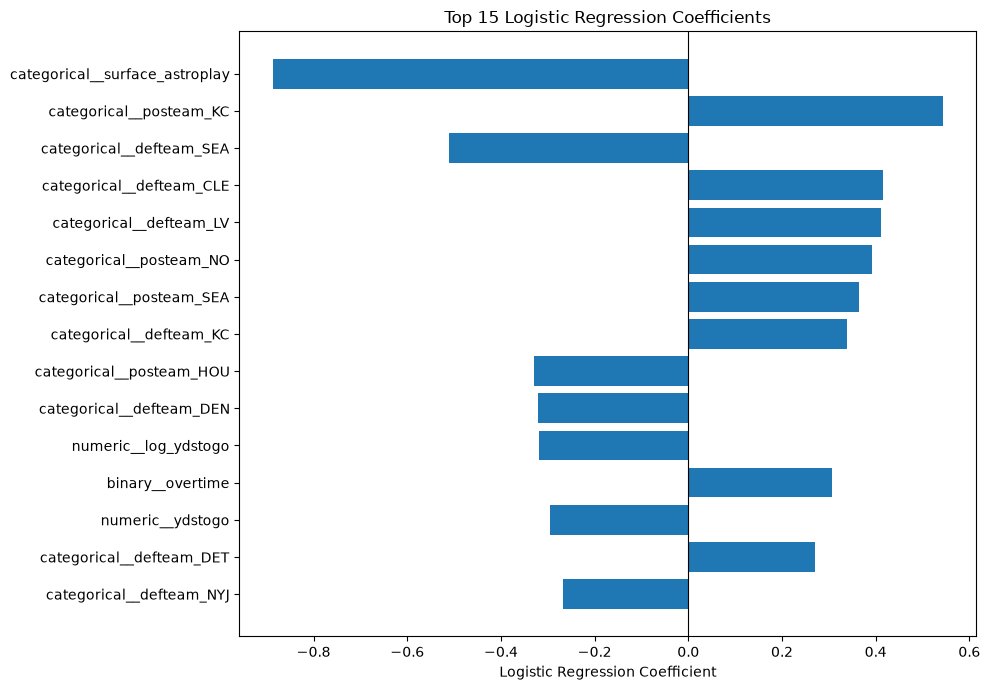

In [9]:
# Cell 9

# Get the feature names after preprocessing
feature_names = logistic_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get the learned logistic regression coefficients
coefficients = logistic_model.named_steps[
    "classifier"
].coef_[0]

# Combine feature names and coefficients
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude
feature_importance["Absolute Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Absolute Coefficient",
    ascending=False
)

print(feature_importance.head(15))

top_features = feature_importance.head(15).iloc[::-1]

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Logistic Regression Coefficient")
plt.title("Top 15 Logistic Regression Coefficients")

plt.tight_layout()
plt.show()


## Feature Analysis

To better understand the Logistic Regression model, the fitted coefficients were extracted and ranked by their absolute magnitude. The 15 largest coefficients were visualized to identify features with the strongest associations with predicted fourth-down conversion probability.

Positive coefficients indicate an association with higher predicted conversion probability, while negative coefficients indicate an association with lower predicted conversion probability, holding other model features constant.

Yards to go is an important predictor because longer distances generally make fourth-down conversions more difficult. Other features, including team identifiers, field position, and game context, may also contribute to the predictions.

However, coefficient magnitudes should be interpreted cautiously. Numeric features were standardized, while categorical features were one-hot encoded, so their coefficients are not directly comparable on the same original scale. Additionally, correlated predictors can affect individual coefficient estimates.

These coefficients describe relationships learned by the model, not necessarily causal effects. A large coefficient does not establish that changing a particular feature would directly change conversion probability.

In [10]:
# Cell 10

print("AstroPlay observations in training data:")
print((train["surface"] == "astroplay").sum())

print("\nSurface distribution:")
print(train["surface"].value_counts(dropna=False))


AstroPlay observations in training data:
13

Surface distribution:
surface
grass         2849
fieldturf     1191
sportturf      263
matrixturf     254
astroturf      191
a_turf         115
astroplay       13
<NA>            11
Name: count, dtype: int64[pyarrow]


In [11]:
# Cell 11

from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessor", make_preprocessor(scale_numeric=False)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest training complete!")


Random Forest training complete!


In [12]:
# Cell 12

rf_probabilities = random_forest_model.predict_proba(
    X_validation
)[:, 1]

rf_predictions = (rf_probabilities >= 0.5).astype(int)

rf_accuracy = accuracy_score(y_validation, rf_predictions)
rf_log_loss = log_loss(y_validation, rf_probabilities)
rf_brier = brier_score_loss(y_validation, rf_probabilities)
rf_auc = roc_auc_score(y_validation, rf_probabilities)

print("Random Forest Results")
print("Accuracy:", rf_accuracy)
print("Log loss:", rf_log_loss)
print("Brier score:", rf_brier)
print("ROC AUC:", rf_auc)


Random Forest Results
Accuracy: 0.6318347509113001
Log loss: 0.6292962815603342
Brier score: 0.21945601953665092
ROC AUC: 0.7008965533555698


In [13]:
# Cell 13

from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting_model = Pipeline([
    ("preprocessor", make_preprocessor(scale_numeric=False)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=10,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting training complete!")


Gradient Boosting training complete!


In [14]:
# Cell 14

gb_probabilities = gradient_boosting_model.predict_proba(
    X_validation
)[:, 1]

gb_predictions = (gb_probabilities >= 0.5).astype(int)

gb_accuracy = accuracy_score(y_validation, gb_predictions)
gb_log_loss = log_loss(y_validation, gb_probabilities)
gb_brier = brier_score_loss(y_validation, gb_probabilities)
gb_auc = roc_auc_score(y_validation, gb_probabilities)

print("Gradient Boosting Results")
print("Accuracy:", gb_accuracy)
print("Log loss:", gb_log_loss)
print("Brier score:", gb_brier)
print("ROC AUC:", gb_auc)


Gradient Boosting Results
Accuracy: 0.6294046172539489
Log loss: 0.6282035471848983
Brier score: 0.21958022086686896
ROC AUC: 0.6920374707259954


In [15]:
# Cell 15

model_results = pd.DataFrame({
    "Model": [
        "Constant Probability",
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        baseline_accuracy,
        logistic_accuracy,
        rf_accuracy,
        gb_accuracy
    ],
    "Log Loss": [
        baseline_log_loss,
        logistic_log_loss,
        rf_log_loss,
        gb_log_loss
    ],
    "Brier Score": [
        baseline_brier,
        logistic_brier,
        rf_brier,
        gb_brier
    ],
    "ROC AUC": [
        0.5,
        logistic_auc,
        rf_auc,
        gb_auc
    ]
})

print(model_results.round(4).to_string(index=False))


               Model  Accuracy  Log Loss  Brier Score  ROC AUC
Constant Probability    0.5188    0.6924       0.2496   0.5000
 Logistic Regression    0.6379    0.6298       0.2209   0.6805
       Random Forest    0.6318    0.6293       0.2195   0.7009
   Gradient Boosting    0.6294    0.6282       0.2196   0.6920


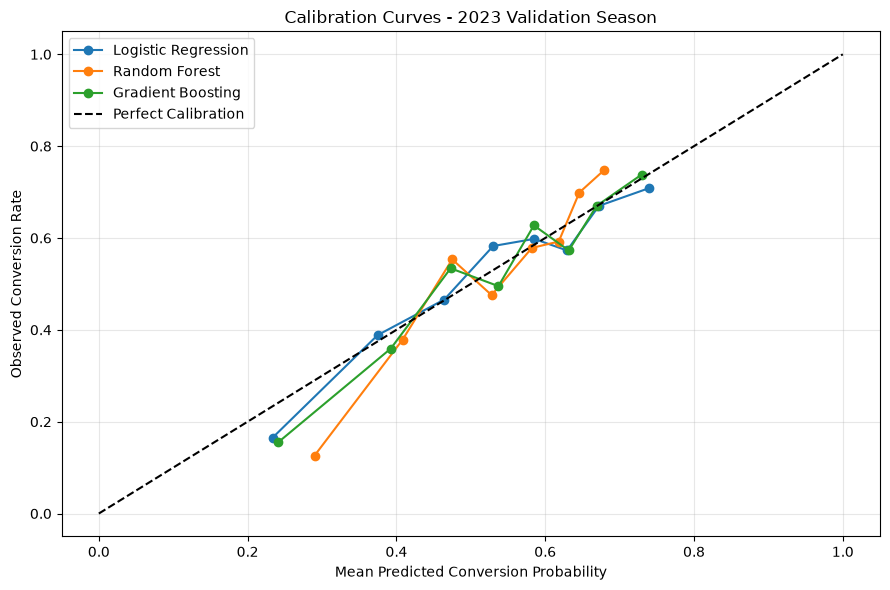

In [16]:
# Cell 16

from sklearn.calibration import calibration_curve

plt.figure(figsize=(9, 6))

model_probabilities = {
    "Logistic Regression": logistic_probabilities,
    "Random Forest": rf_probabilities,
    "Gradient Boosting": gb_probabilities
}

for model_name, probabilities in model_probabilities.items():
    fraction_positive, mean_predicted = calibration_curve(
        y_validation,
        probabilities,
        n_bins=8,
        strategy="quantile"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=model_name
    )

# Perfect calibration reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Conversion Probability")
plt.ylabel("Observed Conversion Rate")
plt.title("Calibration Curves - 2023 Validation Season")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Probability Calibration Analysis

Probability calibration was evaluated using the 2023 validation set. Calibration curves compare predicted fourth-down conversion probabilities with observed conversion rates. A perfectly calibrated model would follow the diagonal reference line.

All three models generally follow the ideal calibration line, although some deviations are present. Logistic Regression appears reasonably well-calibrated across much of its prediction range. Random Forest shows a noticeable deviation at lower predicted probabilities, while Gradient Boosting also exhibits some variation.

The Brier scores are relatively similar across the three models:

- Logistic Regression: 0.2209
- Random Forest: 0.2195
- Gradient Boosting: 0.2196

Random Forest has the lowest Brier score, but the difference compared with Gradient Boosting is small. The calibration curves alone do not establish a clear winner.

Because the project aims to estimate conversion probabilities that could eventually inform fourth-down decisions, calibration is particularly important. A model that predicts probabilities accurately may be more useful for decision-making than one that simply achieves the highest classification accuracy.

## Limitations and Next Steps

### Limitations

Several limitations should be considered when interpreting the preliminary results.

**Selection Bias:** The dataset includes only fourth-down rushing and passing attempts. Teams do not attempt conversions randomly; coaches choose when to go for it based on game context. Consequently, the models learn from situations in which teams actually attempted a conversion and may not generalize equally well to situations where teams typically punt or attempt a field goal.

**Dataset Size:** Although the original play-by-play dataset contains 532,376 plays, only 7,433 meet the filtering criteria for eligible fourth-down conversion attempts. The relatively small sample size may limit the ability of more complex models to learn reliable patterns.

**Feature Availability:** The models use game-state, team, and environmental features intended to represent information available before the snap. Additional verification is needed to ensure that every predictor is available at prediction time and does not introduce information leakage.

**Model Generalization:** Performance has been evaluated on the 2023 validation season. Changes in teams, coaching strategies, and league-wide play patterns may affect how well the models generalize to later seasons.

**Calibration Uncertainty:** The calibration curves are based on 823 validation observations. Individual probability bins contain relatively few plays, so observed conversion rates may vary due to sampling noise.

### Next Steps

Future work will focus on hyperparameter tuning, further investigation of feature importance, and evaluating whether probability calibration can be improved.

After selecting the final modeling approach using validation results, the team will evaluate performance on the held-out 2024–2025 test seasons.

The longer-term goal is to combine estimated fourth-down conversion probabilities with a decision framework that considers the potential outcomes of going for it, punting, or attempting a field goal. Conversion probability alone is not sufficient to determine which decision maximizes a team's chances of winning.

These preliminary models establish a foundation for that future analysis.